# 5 · Structural sizing check

A physics-based wing box on AERO-02, against the statistical wing mass.
Lesson: [05](../docs/lessons/05-structural-sizing-check.md) ·
Theory: [structural sizing check](../docs/structural_sizing_check.md).

In [1]:
import sys
import numpy as np
import matplotlib.pyplot as plt
from acdesign import plotting as P
from acdesign.requirements import B737_800_MISSION as M
from acdesign.units import FT, G0, LB, NMI

P.use_style()
np.set_printoptions(precision=4, suppress=True)
sys.path.insert(0, "../validation")  # cited reference data and the reference aircraft
from reference import b737_800

R = b737_800()
from acdesign.sizing import size_aircraft
from acdesign.structural_sizing_check import wing_box

In [2]:
a = size_aircraft(M)
m = a.masses
r = wing_box(a.geometry.wing, a.geometry.fuselage_diameter, a.W0, a.W0 - a.fuel_mass,
             a.fuel_mass, m["wing"], (m["engines"] + m["nacelles"]) / 2)
print(f"ideal box {r.box_mass:,.0f} kg -> wing {r.wing_mass:,.0f} kg vs class II {m['wing']:,.0f} kg")
print(f"root moment {r.root_moment / 1e6:.2f} MN m, 1-g tip deflection {r.tip_deflection_1g:.2f} m")

ideal box 2,334 kg -> wing 5,227 kg vs class II 5,315 kg
root moment 5.83 MN m, 1-g tip deflection 0.91 m


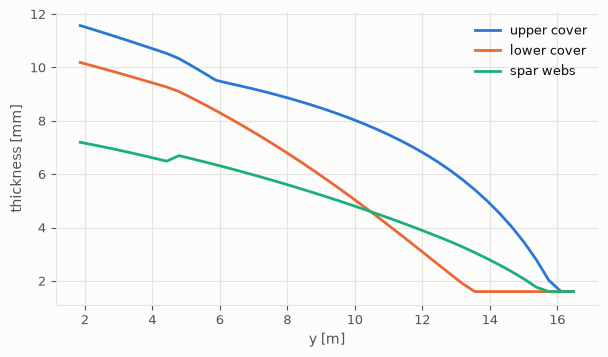

In [3]:
fig, ax = plt.subplots(figsize=(7, 3.8))
ax.plot(r.y, r.t_upper * 1e3, label="upper cover")
ax.plot(r.y, r.t_lower * 1e3, label="lower cover")
ax.plot(r.y, r.t_web * 1e3, label="spar webs")
ax.set_xlabel("y [m]"); ax.set_ylabel("thickness [mm]"); ax.legend();